# 01 · Data, model and evaluation

Telecom customer churn (IBM Telco Customer Churn). This notebook covers the problem definition, the data,
the evaluation protocol and the models we will explain later. The logic lives in `src/`; the notebook only
calls it and comments on the results.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone

sys.path.insert(0, str(Path.cwd().parent))  # make `src` importable when the notebook runs from notebooks/
from src.data import download, load_clean
from src.modeling import (MAX_AUC_GAP, SEED, SUSPICIOUS_AUC, churn_metrics, customer_costs, cv_and_gap,
                          expected_cost, make_models, oof_proba, pick_threshold, split)
from src.plots import FIGURES, calibration_bins, calibration_plot, save, use_style

use_style()

## 1. Task and data

**Task.** Binary classification. Input: the profile of a customer (contract, services, billing, tenure).
Output: whether the customer churned (1) or not (0). **Stakeholder.** The retention team, which has a limited
budget and decides whom to contact and with which offer.

**Data.** IBM sample data set, 7,043 customers x 21 columns, downloaded by `python -m src.data`.

In [2]:
X, y = load_clean(download())
print(f"{len(X)} customers, {X.shape[1]} features, churn rate {y.mean():.4f}")
print(f"numeric: {list(X.select_dtypes('number').columns)}")
print(f"categorical: {X.select_dtypes(exclude='number').shape[1]} columns of text")

7043 customers, 19 features, churn rate 0.2654
numeric: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
categorical: 15 columns of text


In [3]:
# Churn is driven by the type of contract long before any model is fitted.
(pd.concat([X["Contract"], y], axis=1).groupby("Contract")["Churn"]
   .agg(customers="size", churn_rate="mean").round(3))

,customers,churn_rate
Contract,,
Month-to-month,3875,0.427
One year,1473,0.113
Two year,1695,0.028


**Key preprocessing.**
- `customerID` is dropped: it identifies a row, it is not a feature.
- `TotalCharges` is text in the raw file because 11 rows are blank. All 11 are customers with `tenure = 0`
  (signed up, not billed yet), so 0 is their true value; `load_clean` refuses any other blank.
- This cleaning is row-wise and fits nothing, so it cannot leak. Everything that *is* fitted (one-hot encoding,
  scaling for the linear model) lives inside the sklearn `Pipeline`, and is refitted on every training fold.

In [4]:
duplicates = pd.concat([X, y], axis=1).duplicated().sum()
print(f"{duplicates} rows are exact duplicates of another row (customerID aside)")

22 rows are exact duplicates of another row (customerID aside)


The duplicates are kept: they are plausible different customers with identical profiles, and dropping them
would change the population. A duplicate may fall on both sides of the split, which makes the test estimate
very slightly optimistic (22 of 7,043 rows).

## 2. Evaluation protocol

- **Split.** Stratified 80/20 with a fixed seed. Telco is cross-sectional (one row per customer, no time axis),
  so a random split is appropriate; a time-aware split would need dates we do not have.
- **Selection.** Hyperparameters are chosen by 5-fold CV **on the training set only**. The CV number reported is
  *nested*: the search is redone inside every outer fold, so it is not inflated by picking the best
  configuration on the same folds.
- **Test set.** Only scored, never used to fit or tune.
- **Imbalance.** 26.5 % churn. No resampling and no class weights: the decision threshold and the
  churn-class metrics deal with it (next section), which avoids distorting the probabilities.
- **"Not overfitted".** Defined before tuning as train AUC minus CV AUC below `MAX_AUC_GAP`.

In [5]:
X_train, X_test, y_train, y_test = split(X, y)
print(f"train {len(X_train)} (churn {y_train.mean():.4f}) | test {len(X_test)} (churn {y_test.mean():.4f})")
print(f"max allowed train-CV AUC gap: {MAX_AUC_GAP}")

train 5634 (churn 0.2654) | test 1409 (churn 0.2654)
max allowed train-CV AUC gap: 0.03


## 3. Models

1. **Majority class.** Always predicts the prior: the floor every model must beat.
2. **Logistic regression** (L2, tuned `C`, standardised numerics). The interpretable reference: its coefficients
   are an explanation we can compare against.
3. **XGBoost** (tuned depth and number of trees, `subsample` and `colsample_bytree` 0.8). The main model, whose
   explanations we will study with TreeSHAP.

In [6]:
models = make_models()
table = pd.DataFrame({name: cv_and_gap(est, X_train, y_train, X_test, y_test)
                      for name, est in models.items()}).T
table.round(4)

,train_auc,cv_auc,cv_std,test_auc,gap,cv_pr_auc,test_pr_auc
majority,0.500,0.5000,0.0000,0.5000,0.0000,0.2654,0.2654
logistic,0.850,0.8463,0.0129,0.8413,0.0037,0.6607,0.6285
xgboost,0.859,0.8508,0.0117,0.8481,0.0082,0.6720,0.6699


In [7]:
# Guardrails. A failure here stops the notebook instead of hiding a problem.
tuned_names = ["logistic", "xgboost"]
tuned = table.loc[tuned_names]
assert (tuned["gap"] < MAX_AUC_GAP).all(), f"overfitting: gap above {MAX_AUC_GAP}"
assert (table["cv_auc"] < SUSPICIOUS_AUC).all(), f"CV AUC above {SUSPICIOUS_AUC}: rule out leakage first"
assert (tuned["cv_auc"] > table.loc["majority", "cv_auc"] + 0.2).all(), "models barely beat the majority baseline"
print("checks passed: no overfitting gap, no suspicious AUC, both models clearly above the majority baseline")

checks passed: no overfitting gap, no suspicious AUC, both models clearly above the majority baseline


In [8]:
# Which configuration wins when the search sees the whole training set.
final = {name: clone(est).fit(X_train, y_train) for name, est in models.items()}
{name: model.best_params_ for name, model in final.items() if hasattr(model, "best_params_")}

{'logistic': {'model__C': 10},
 'xgboost': {'model__max_depth': 1, 'model__n_estimators': 600}}

### Reading the results

- **In the expected range, no sign of leakage.** CV AUC is 0.846 (logistic) and 0.851 (XGBoost). Published
  work on this data set reports about 0.84-0.86; an AUC above 0.90 would have been treated as leakage.
- **Not overfitted.** The train-CV gap is 0.004 and 0.008, between 4 and 8 times below the 0.03 we allowed,
  and the test AUC (0.841, 0.848) is within one fold standard deviation (0.012) of the CV estimate.
- **The churn class is being found.** PR-AUC of a model with no skill equals the churn rate, 0.265 (the
  majority row). Both models reach 0.66-0.67 in CV.
- **XGBoost is the main model, but the margin is small.** Its ROC-AUC is ahead by 0.005 in CV, less than the
  spread between folds (0.012), so on ROC-AUC alone the two models are not separable. It is ahead on PR-AUC
  too (CV 0.672 vs 0.661, test 0.670 vs 0.628), but we have not measured the fold spread of PR-AUC, so we do
  not claim more than "never worse". Logistic regression stays as the interpretable reference.
- **The best XGBoost is a set of depth-1 trees (stumps).** Boosted stumps are an *additive* model: each feature
  contributes on its own, with no interactions. So, on this data set, interactions do not seem to be needed to predict well (an inference: depth 1 is also the lowest value in the grid). *Inference to check in the XAI notebook:* SHAP values of such a model are the per-feature effects
  themselves, so LR and XGBoost should tell a similar story.
- **Grid edges.** The winners sit at the edge of the grid (depth 1 is the lowest possible value; 600 trees the
  highest tried; `C` 10-100). We widened the grid twice using training folds only (and switched to one column
  per Yes/No feature): CV AUC went 0.8503 -> 0.8505 -> 0.8508. The AUC surface is a plateau, with differences
  far below the fold-to-fold noise, so we stopped tuning.
- **AUC is only the first look.** With 26.5 % churn the decision depends on the threshold, and accuracy alone
  is misleading (a model that never predicts churn is 73.5 % accurate). Churn-class metrics come next.

## 4. Decision threshold and cost

A probability is not yet a decision: the retention team needs a rule "contact this customer if the
probability is at least *t*". Two mistakes are possible. A **missed churner** (false negative) loses the
customer; a **wasted offer** (false positive) spends the retention budget on someone who was staying.

**Assumption, not a measurement:** a missed churner costs `MAIN_RATIO = 5` wasted offers (the ratio used in one of
the reviewed papers). The real ratio depends on customer value and offer cost, which this data set does not
have, so we repeat the analysis for 2 and 10 as a sensitivity check.

The threshold that minimises the expected cost is chosen on **out-of-fold predictions of the training set**
(each customer scored by a model that never saw them), never on the test set. For perfectly calibrated
probabilities that optimum is exactly `1 / (1 + ratio)`, so the analytic value below is a consistency check.
It is only indirect evidence on its own; the calibration curve in section 5 is the direct check.

In [9]:
COST_RATIOS, MAIN_RATIO = (2, 5, 10), 5
proba_oof = {name: oof_proba(models[name], X_train, y_train) for name in tuned_names}

thresholds = pd.DataFrame({name: {r: pick_threshold(y_train, p, r) for r in COST_RATIOS}
                           for name, p in proba_oof.items()})
thresholds.insert(0, "analytic 1/(1+r)", [1 / (1 + r) for r in COST_RATIOS])
thresholds.index.name = "cost ratio"
thresholds.round(2)

,analytic 1/(1+r),logistic,xgboost
cost ratio,,,
2,0.33,0.35,0.37
5,0.17,0.17,0.17
10,0.09,0.08,0.07


**Test-set results at the reference ratio.** Same churn-class metrics for every model, next to the majority
baseline (which never flags a churner). Accuracy is shown only to make the point that it hides the problem.

In [10]:
proba_test = {name: model.predict_proba(X_test)[:, 1] for name, model in final.items()}
threshold_of = {"majority": 0.5, **{name: thresholds.loc[MAIN_RATIO, name] for name in tuned_names}}

at_reference = pd.DataFrame({name: {"threshold": threshold_of[name],
                                    **churn_metrics(y_test, proba_test[name], threshold_of[name])}
                             for name in proba_test}).T
at_reference.round(3)

,threshold,precision,recall,f1,accuracy,pr_auc,brier
majority,0.50,0.000,0.000,0.000,0.735,0.265,0.195
logistic,0.17,0.450,0.898,0.600,0.682,0.628,0.139
xgboost,0.17,0.456,0.882,0.602,0.690,0.670,0.134


**Expected cost per customer on the test set** (a missed churner costs *ratio*, a wasted offer costs 1). The
fair comparison is not the majority classifier but the two policies that need no model: contact nobody, or
contact everybody. This is the cost of the *classification errors* under our assumed ratio; it is not the
effect of a retention campaign.

In [11]:
everybody = np.ones(len(y_test))
nobody = np.zeros(len(y_test))
cost = pd.DataFrame({r: {"contact nobody": expected_cost(y_test, nobody, r),
                         "contact everybody": expected_cost(y_test, everybody, r),
                         **{name: expected_cost(y_test, proba_test[name] >= thresholds.loc[r, name], r)
                            for name in tuned_names}}
                     for r in COST_RATIOS})
cost.columns.name = "cost ratio"
best_policy_without_a_model = cost.loc[["contact nobody", "contact everybody"]].min()
saving = (1 - cost.loc[tuned_names] / best_policy_without_a_model).mul(100)
print("Expected cost per customer:")
display(cost.round(3))
print("Saving against the better of 'contact nobody' / 'contact everybody', in %:")
display(saving.round(1))

Expected cost per customer:


cost ratio,2,5,10
contact nobody,0.531,1.327,2.654
contact everybody,0.735,0.735,0.735
logistic,0.311,0.426,0.486
xgboost,0.297,0.435,0.499


Saving against the better of 'contact nobody' / 'contact everybody', in %:


cost ratio,2,5,10
logistic,41.4,42.0,33.8
xgboost,44.0,40.8,32.1


Is the cost difference between the two models larger than sampling noise? A **paired bootstrap** resamples the
1,409 test customers (same customers for both models) and recomputes the difference of average costs.

In [12]:
rng = np.random.default_rng(SEED)
resamples = rng.integers(0, len(y_test), size=(2000, len(y_test)))
difference = {}
for r in COST_RATIOS:
    per_customer = (customer_costs(y_test, proba_test["logistic"] >= thresholds.loc[r, "logistic"], r)
                    - customer_costs(y_test, proba_test["xgboost"] >= thresholds.loc[r, "xgboost"], r))
    low, high = np.percentile(per_customer[resamples].mean(axis=1), [2.5, 97.5])
    difference[r] = {"logistic minus xgboost": per_customer.mean(), "95% low": low, "95% high": high}
difference = pd.DataFrame(difference).T.rename_axis("cost ratio")
difference.round(3)

,logistic minus xgboost,95% low,95% high
cost ratio,,,
2,0.013,-0.004,0.033
5,-0.009,-0.038,0.021
10,-0.013,-0.057,0.034


## 5. Calibration

If the probabilities are calibrated, among customers scored around 0.3 about 30 % churn. That is what makes a
cost-based threshold meaningful. The curve uses the out-of-fold predictions of the training set (5,634
customers, four times more than the test set, so each bin is less noisy).

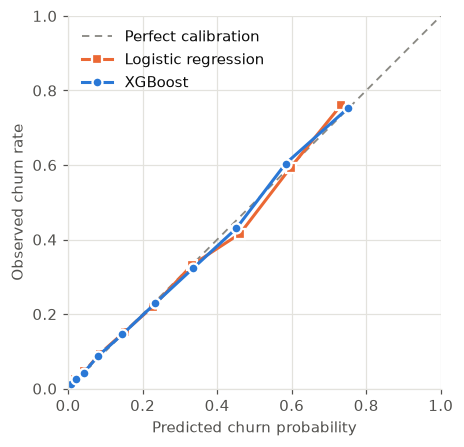

Worst bin deviation (out-of-fold): {'logistic': 0.045, 'xgboost': 0.021}
Brier score on test (lower is better; the majority baseline is the reference):


majority    0.195
logistic    0.139
xgboost     0.134
Name: brier, dtype: float64

In [13]:
fig, ax = plt.subplots(figsize=(4.6, 4.4))
calibration_plot(y_train, proba_oof, ax)
save(fig, "calibration.png")
plt.show()

# Largest gap between observed churn rate and mean predicted probability over the 10 bins.
worst_bin = {name: np.abs(np.subtract(*calibration_bins(y_train, p))).max()
             for name, p in proba_oof.items()}
print("Worst bin deviation (out-of-fold):", {k: round(float(v), 3) for k, v in worst_bin.items()})
print("Brier score on test (lower is better; the majority baseline is the reference):")
at_reference["brier"].round(3)

### Reading sections 4 and 5

- **The thresholds are consistent with calibrated probabilities.** Those found on out-of-fold predictions (0.17
  for ratio 5) equal the analytic `1/(1+ratio)`, and stay within about 0.04 of it for ratios 2 and 10. This is only indirect evidence; the direct evidence is the calibration curve, where both models follow the diagonal. This is the benefit of not resampling the classes.
- **The threshold is a business decision, not a modelling one.** It moves from about 0.35 to 0.17 to 0.08 as a
  missed churner goes from 2 to 5 to 10 times as costly as a wasted offer. We do not know the real ratio, so any
  number we later quote is conditional on it.
- **Accuracy would pick the wrong model.** At the reference threshold both models are *less* accurate (0.68-0.69)
  than the majority classifier (0.735), yet they find 88-90 % of the churners against 0 %. Precision is 0.45-0.46:
  about 45 of every 100 customers contacted are real churners, against a base rate of 26.5 %.
- **Against the honest baseline the models cut the cost by 32-44 %.** The comparison is with the better of "contact
  nobody" and "contact everybody" (a model-free team would do one of them), not with the majority class. The saving
  is 41-42 % at ratio 5 and smaller (32-34 %) at ratio 10. It is a saving in *classification errors* under our assumed
  costs; it is not the measured effect of a retention campaign, which would also need to know who responds to an offer.
- **Logistic regression and XGBoost cost the same.** The paired bootstrap intervals of their cost difference
  include zero for all three ratios (e.g. -0.038 to 0.021 at ratio 5). XGBoost is ahead on PR-AUC and Brier, but
  these gains do not survive as a cheaper decision on 1,409 test customers.
- **Calibration is good but not perfect.** The worst bin is off by 0.045 for logistic regression and 0.021 for
  XGBoost. Brier is 29-31 % below the no-skill 0.195. We did not recalibrate: the probabilities are already close,
  and a recalibration would need its own held-out data.

In [14]:
out = FIGURES.parent / "metrics.json"
out.write_text(json.dumps({
    "seed": SEED,
    "auc": table.round(4).to_dict("index"),
    "cost_ratios": list(COST_RATIOS),
    "thresholds": thresholds.round(3).to_dict("index"),
    "test_at_reference_ratio": at_reference.round(4).to_dict("index"),
    "test_expected_cost": cost.round(4).to_dict("index"),
    "test_cost_difference_logistic_minus_xgboost": difference.round(4).to_dict("index"),
}, indent=2))
print("saved", out.name)

saved metrics.json
